In [1]:
# Experiment 04 — Grover Search Using Three Qubits

In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np

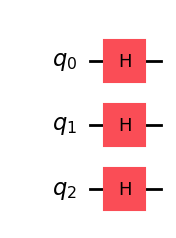

Initial Probabilities:
{np.str_('000'): np.float64(0.12499999999999994), np.str_('001'): np.float64(0.12499999999999994), np.str_('010'): np.float64(0.12499999999999994), np.str_('011'): np.float64(0.12499999999999994), np.str_('100'): np.float64(0.12499999999999994), np.str_('101'): np.float64(0.12499999999999994), np.str_('110'): np.float64(0.12499999999999994), np.str_('111'): np.float64(0.12499999999999994)}


In [3]:
# Create a three-qubit circuit
qc = QuantumCircuit(3)

# Apply Hadamard gates to all qubits
qc.h([0, 1, 2])

# Display the circuit
display(qc.draw("mpl"))

# Check the initial probabilities
initial_state = Statevector.from_instruction(qc)

print("Initial Probabilities:")
print(initial_state.probabilities_dict())

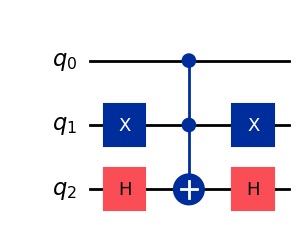

In [4]:
# Create an oracle to mark |101>
oracle = QuantumCircuit(3)

# Flip q1 because the target's middle bit is 0
oracle.x(1)

# Apply a phase flip to the target state
oracle.h(2)
oracle.mcx([0, 1], 2)
oracle.h(2)

oracle.x(1)

# Display the oracle circuit
display(oracle.draw("mpl"))

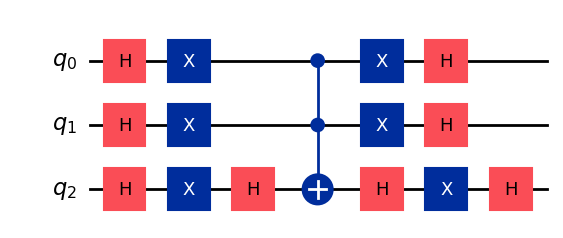

In [6]:
# Create the diffusion operator
diffuser = QuantumCircuit(3)

diffuser.h([0, 1, 2])
diffuser.x([0, 1, 2])

# Apply the controlled phase flip
diffuser.h(2)
diffuser.mcx([0, 1], 2)
diffuser.h(2)

diffuser.x([0, 1, 2])
diffuser.h([0, 1, 2])

# Display the diffusion circuit
display(diffuser.draw("mpl"))

Grover Iteration 1 Completed
Grover Iteration 2 Completed


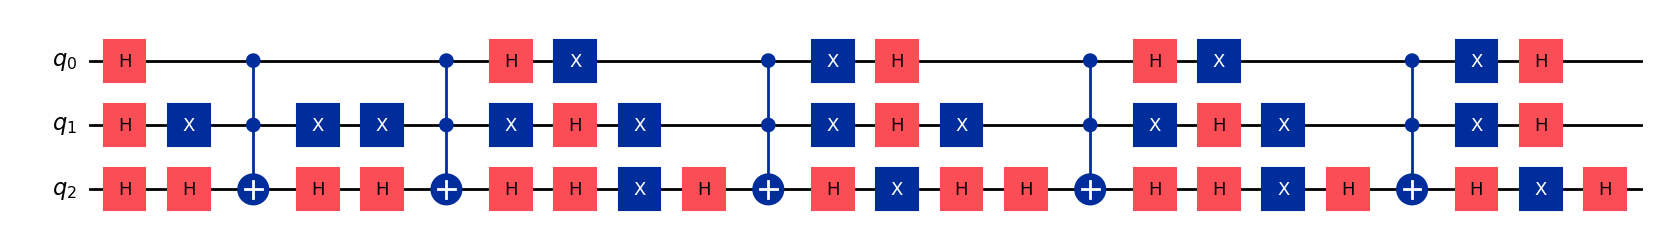

In [7]:
# Apply the oracle and diffuser twice
for i in range(2):
    qc.compose(oracle, inplace=True)
    qc.compose(diffuser, inplace=True)

    print(f"Grover Iteration {i + 1} Completed")

# Display the complete Grover circuit
display(qc.draw("mpl"))

In [8]:
# Calculate the final quantum state
final_state = Statevector.from_instruction(qc)

print("Final Statevector:")
print(np.round(final_state.data, 4))

print("\nFinal Probabilities:")
print({
    str(k): round(float(v), 4)
    for k, v in final_state.probabilities_dict().items()
})

Final Statevector:
[0.1768+0.j 0.1768+0.j 0.1768+0.j 0.1768+0.j 0.1768+0.j 0.8839+0.j
 0.1768+0.j 0.1768+0.j]

Final Probabilities:
{'000': 0.0312, '001': 0.0312, '010': 0.0312, '011': 0.0312, '100': 0.0312, '101': 0.7812, '110': 0.0312, '111': 0.0312}


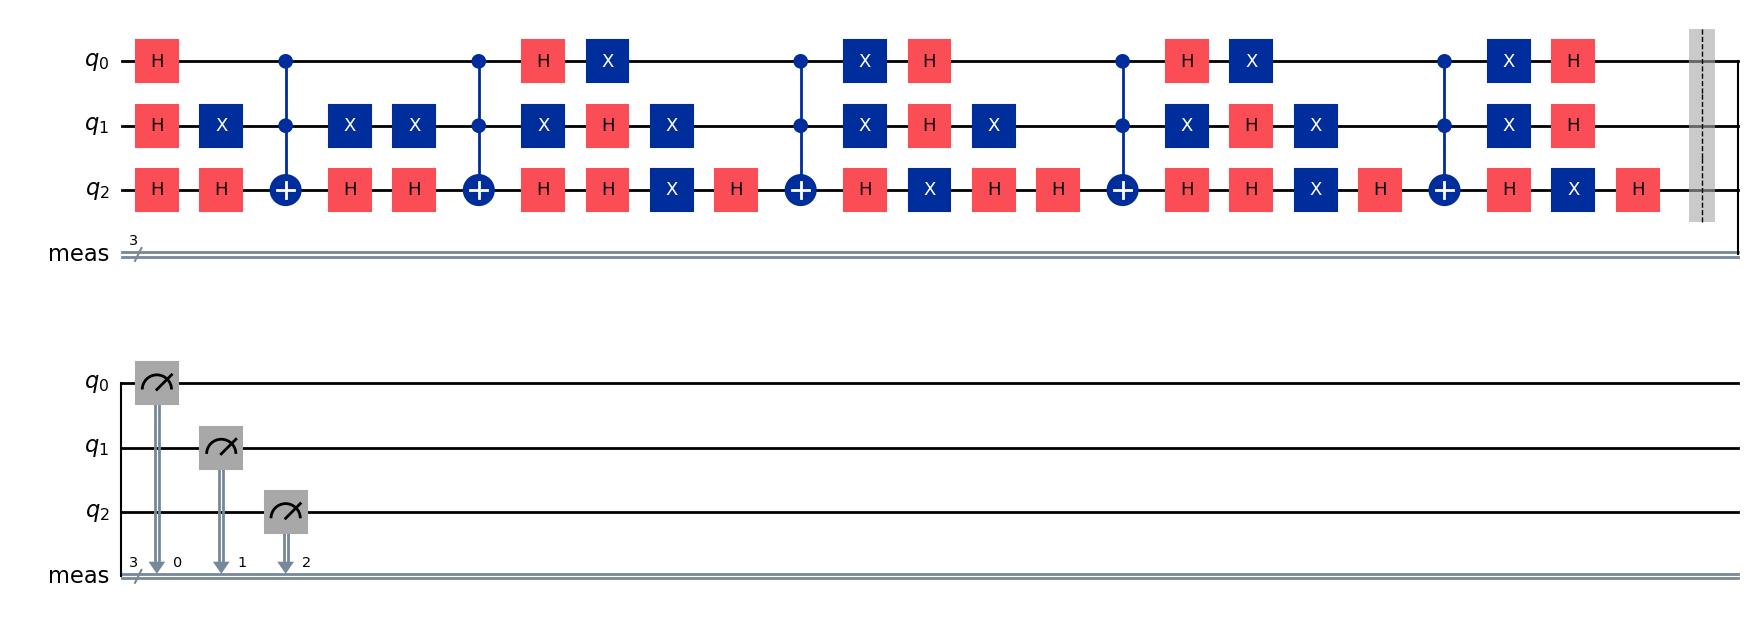

Measurement Counts: {'101': 820, '001': 30, '111': 26, '010': 29, '100': 36, '011': 39, '000': 19, '110': 25}


In [9]:
# Add measurements to all qubits
qc_measure = qc.copy()
qc_measure.measure_all()

# Display the measurement circuit
display(qc_measure.draw("mpl"))

# Run the circuit 1024 times
simulator = AerSimulator()

result = simulator.run(
    transpile(qc_measure, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Measurement Counts:", counts)

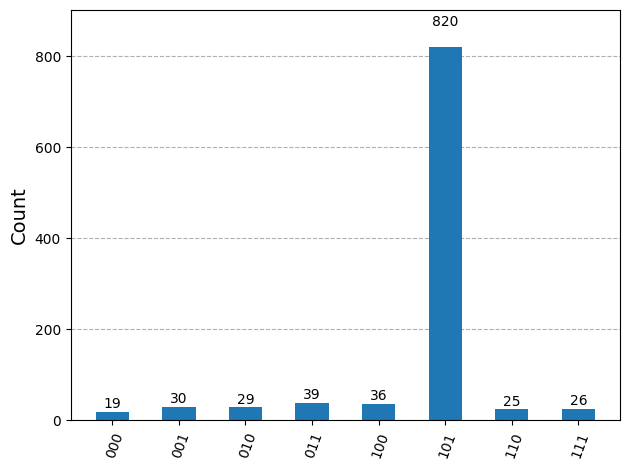

Target State: 101
Most Frequent State: 101
Success Probability: 0.8008


In [10]:
# Display the measurement histogram
display(plot_histogram(counts))

# Calculate the success probability
target = "101"

success_probability = counts.get(target, 0) / sum(counts.values())

print("Target State:", target)
print("Most Frequent State:", max(counts, key=counts.get))
print("Success Probability:", round(success_probability, 4))